# Inverse designed grating coupler

Inverse design of grating coupler on SOI for angled fiber. (inverse design not available in free version)

## Config

In [38]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

path = os.path.join("runs", "GC_topopt")

wavelength = 1.55
bandwidth = 0.10
nwls = 1
wavelengths = np.linspace(wavelength - bandwidth / 2, wavelength + bandwidth / 2, nwls)

# simulation parameters
nres = 5
boundaries = ["PML", ["PEC", "PML"], "PML"]
PML_decay = [0.01, 0.3, 0.01]
relative_courant = 0.95
stop_decay=None

# horizontal dimensions
r =5
R =1.5* r
w_design = 2 * R
l_design = w_design
w_wg = 0.5
l_wg = 5
flare = 20  # waveguide flare full angle (deg)

margin = 1

# vertical dimensions
theta = 10 * np.pi / 180 # beam angle
h_wg = 0.22
h_slab = 0.15
h_rib = 0.07

zmargin = .6
port_offset = 0.3
source_offset = 0.3
z_port = h_wg + port_offset

zmin = -zmargin
zmax = h_wg + port_offset + source_offset

# movie parameters
shot_every = 5

views = [
    lumi.view("Ey", y=0, z=h_slab+h_rib/2,mirrors = ["y-"]),
]

# materials
core = "Si"
clad = "SiO2"
materials = {
    "Si": lumi.material(3.45),
    "SiO2": lumi.material(1.44),
}

n_core = materials[core]["n"]
n_clad = materials[clad]["n"]
lambda_core = wavelength / n_core
lambda_clad = wavelength / n_clad
dx = lambda_core / nres

background = clad
materials["design"] = lumi.placeholder_material(n_core)

# layer stack. lower mesh order layers override higher mesh order layers.
WG = (1, 0)
CLAD = (2, 0)
RIB = (101, 0)
SLAB = (102, 0)
DESIGN = (1001, 0)

layers = {
    "design": LayerLevel(
        layer=LogicalLayer(layer=DESIGN),
        zmin=h_slab,
        thickness=h_rib,
        material="design",
        mesh_order=1,
    ),
    "rib": LayerLevel(
        layer=LogicalLayer(layer=SLAB),
        zmin=h_slab,
        thickness=h_rib,
        material=core,
        mesh_order=101,
    ),
    "slab": LayerLevel(
        layer=LogicalLayer(layer=SLAB),
        zmin=0,
        thickness=h_slab,
        material=core,
        mesh_order=102,
    ),
    "core": LayerLevel(
        layer=LogicalLayer(layer=WG),
        zmin=0,
        thickness=h_wg,
        material=core,
        mesh_order=200,
    ),
}
layer_stack = LayerStack(layers=layers)

## Geometry

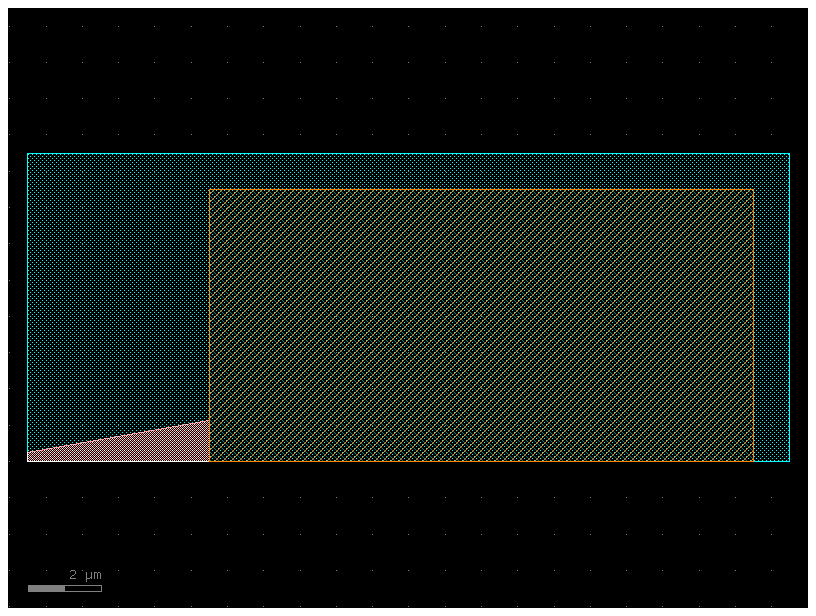

In [39]:
# Build the gdsfactory component to be optimized (upper half, mirrored about y=0).
ox_design = -l_design + R
x_wg = ox_design - l_wg

c = gf.Component()
for layer in (DESIGN, SLAB):
    rect = c << gf.components.rectangle(size=(l_design, w_design / 2), layer=layer)
    rect.movex(ox_design)

w_flare = w_wg / 2 + l_wg * np.tan(np.radians(flare / 2))
c.add_polygon([(x_wg, 0), (x_wg, w_wg / 2), (ox_design, w_flare), (ox_design, 0)], layer=WG)

c << gf.components.bbox(component=c, layer=CLAD, top=margin, right=margin)

c.add_port("o1", center=(x_wg, 0), width=w_wg / 2, orientation=180, layer=WG)

c.plot()

In [40]:
frames = [
    lumi.plane_frame(
        "wg",
        start=[-w_wg / 2 - margin, zmin],
        stop=[0, zmax],
        boundaries=[("PML", "PEC"), "PML"],
        wls_mode_solver=[wavelength],
    ),
    lumi.plane_frame(
        "beam",
        modes=[
            [
                lumi.gaussian_mode(
                    r,
                    R,
                    Z=1 / n_clad,
                    dx=dx,
                    theta=theta,
                    wl=wavelength,
                    half="y+",
                )
            ]
        ],
        start=[-R, 0],
        stop=[R, R],
    ),
]

origin = [
    np.sin(theta) * (source_offset + port_offset),
    0,
    h_wg + port_offset + source_offset,
]
basis = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
sources = [
    lumi.source(
        "o2",
        origin,
        basis,
        wl=wavelength,
        bandwidth=max(max(wavelengths) - min(wavelengths), wavelength / 4),
        frame="beam",
    )
]

origin = [np.sin(theta) * (port_offset), 0, h_wg + port_offset]
monitors = [
    lumi.gf_monitor("o1", c, layer_stack, frame="wg"),
    lumi.monitor("o2", origin, basis, frame="beam"),
]

tmax =     1.3/ wavelength    * (
        (port_offset + source_offset) / np.cos(theta) * n_clad
        + (l_design +R+r+ l_wg) * n_core
    )    + sources[0]["duration"]

bbox = c.bbox_np().tolist()
bbox[0].append(zmin)
bbox[1].append(zmax)

In [41]:
optimizer = lumi.optimizer(
    stoploss=0.3,
    lowloss=0.7,
    iters=15,
    contrast=0.3,
    momentum=0.7,
)
targets = [
    lumi.target(src="o2@0-", dst="o1@0+", target=1, weight=1 / nwls, wl=wl)
    for wl in wavelengths
]
designs = [
    lumi.design(
        name="design",
        lmin = 0.1,
        layer=DESIGN,
        fill_material=core,
        void_material=clad,
        component=c,
        layer_stack=layer_stack,
        materials=materials,
        repdims=[3],
        anchordims=[],
    )
]

## Solve

showing modes for wavelength 1.55
mode Boundary conditions: 00A0


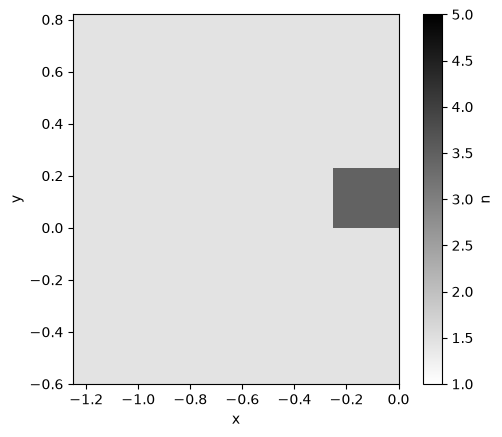

wg/1.55 mode 0 (neff=2.441+0.000j)
saving mode to runs/GC_topopt/modes/wg/1.55/0.npz
using simulation folder runs/GC_topopt


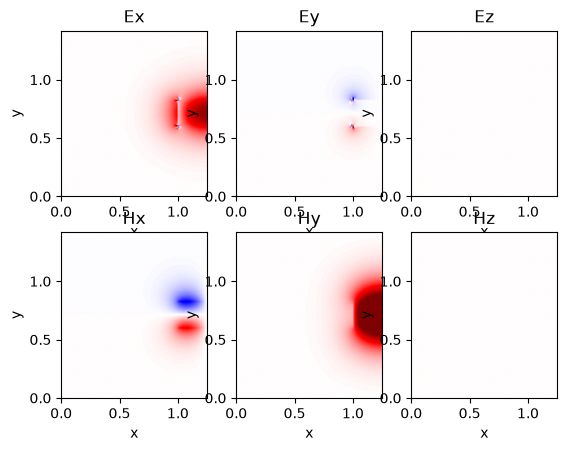

In [42]:
lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
lumi.setup(
    path=path,
    wl=wavelength,
    wls=wavelengths,
    frames=frames,
    monitors=monitors,
    sources=sources,
    boundaries=boundaries,
    bbox=bbox,
    materials=materials,
    background=background,
    nres=nres,
    tmax=tmax,
    PML_decay=PML_decay,
    relative_courant=relative_courant,
    stop_decay=stop_decay,
    shot_every=shot_every,
    views=views,
    designs=designs,
    targets=targets,
    optimizer=optimizer,
    # load_designs=['design']
)

## Movie


In [44]:
lumi.movie(path)

no views found, skipping movie generation.


FileNotFoundError: [Errno 2] No such file or directory: 'runs/GC_topopt/shots'